In [28]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [29]:
#Set time to extract historical data
years = 15
endDate = dt.datetime.now()
startDate = endDate - dt.timedelta(days = 365*years)


In [30]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [31]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate)
    adj_close_df[ticker] = data['Adj Close']
print(adj_close_df)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2008-11-20   56.466183  48.461815   73.449997   22.358791   28.019484
2008-11-21   59.512123  48.222321   78.849998   23.329767   29.609612
2008-11-24   63.635777  48.015228   80.910004   24.755627   31.373066
2008-11-25   64.107277  48.843708   80.870003   24.641912   31.810177
2008-11-26   66.584457  49.147945   80.379997   25.674122   32.985806
...                ...        ...         ...         ...         ...
2023-11-13  440.190002  69.660004  180.509995  377.209991  217.330002
2023-11-14  448.730011  7

In [32]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2008-11-21  0.052538 -0.004954  0.070942  0.042511  0.055199
2008-11-24  0.066996 -0.004304  0.025790  0.059323  0.057851
2008-11-25  0.007382  0.017107 -0.000495 -0.004604  0.013837
2008-11-26  0.037913  0.006209 -0.006078  0.041035  0.036291
2008-11-28  0.012510 -0.003166 -0.000871 -0.007867  0.012037
...              ...       ...       ...       ...       ...
2023-11-13 -0.000954 -0.000287  0.005555 -0.003123 -0.000598
2023-11-14  0.019215  0.012128  0.008880  0.021298  0.021936
2023-11-15  0.002115 -0.005546 -0.002639  0.000752  0.002473
2023-11-16  0.001222  0.005972  0.011223  0.000855 -0.000674
2023-11-17 -0.000400  0.000424  0.001069 -0.002023  0.001212

[3773 rows x 5 columns]


In [33]:
#create a function to calculate portfolio expected return
def expected_return(weights, log_returns):
    return np.sum(log_returns.mean()*weights) #Note that expected return are based on historical data. Ideally a market expert comes up with their own expected returns based on current market data


In [94]:
#Define standard deviation
def standard_deviation(weights, cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)

In [95]:
#Create covariance matrix
cov_matrix = log_returns.cov()
print(cov_matrix)

          SPY           BND       GLD           QQQ       VTI
SPY  0.000138 -1.208436e-06  0.000008  1.464279e-04  0.000140
BND -0.000001  9.421033e-06  0.000009 -4.102833e-07 -0.000001
GLD  0.000008  8.588235e-06  0.000105  8.204728e-06  0.000009
QQQ  0.000146 -4.102833e-07  0.000008  1.812282e-04  0.000150
VTI  0.000140 -1.072534e-06  0.000009  1.496567e-04  0.000144


In [108]:
#Create a equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
portfolio_expected_return = expected_return(weights, log_returns)
portfolio_std_dev = standard_deviation(weights, cov_matrix)

In [109]:
#random Z score generator
def random_z_score():
    return np.random.normal(0,1)

In [113]:
days = 30
def scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days):
    return portfolio_value * portfolio_expected_return * days + portfolio_value * portfolio_std_dev * z_score * np.sqrt(days)

In [114]:
#run 10000 simulations
simulations = 10000
scenarioReturn = []

for i in range(simulations):
    z_score = random_z_score()
    scenarioReturn.append(scenario_gain_loss(portfolio_value, portfolio_std_dev, z_score, days))

In [115]:
#specify confidence interval
confidence_interval = 0.99
VaR = -np.percentile(scenarioReturn, 100*(1-confidence_interval))
print(VaR)

87067.15911096608


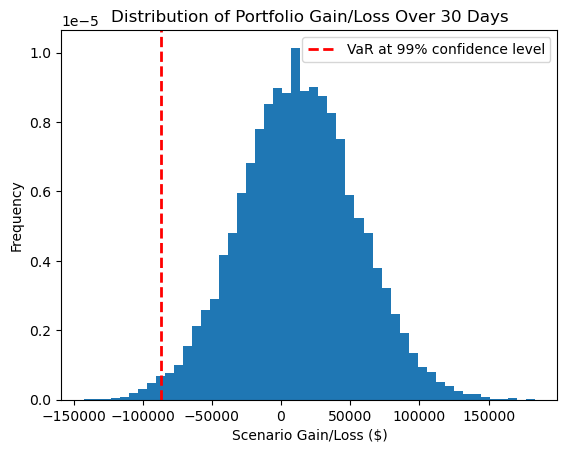

In [105]:
### Plot the results of all 10000 scenarios
plt.hist(scenarioReturn, bins=50, density=True)
plt.xlabel('Scenario Gain/Loss ($)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio Gain/Loss Over {days} Days')
plt.axvline(-VaR, color='r', linestyle='dashed', linewidth=2, label=f'VaR at {confidence_interval:.0%} confidence level')
plt.legend()
plt.show()